# Sensitivity analysis of BNGL models

Local and global sensitivity analysis with `bionetgen_tools.BNGLSimulator`, which runs the model with bngsim.

- **Local** sensitivities are normalized derivatives, $(\partial O/\partial p)(p/O)$, along a trajectory. They come
  from bngsim's forward sensitivity analysis: exact, all parameters in one run. `method="fd"` uses one-at-a-time
  finite differences instead, as the original version of this notebook did.
- **Global** sensitivities are regression coefficients of log10(output) on log10(parameters), over a Latin hypercube
  sample that spans orders of magnitude. Samples run in parallel.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bionetgen_tools import BNGLSimulator

## Example: FcεRI model

In [2]:
simulator = BNGLSimulator("../models/fceri_starter.bngl")

print(f"Model loaded: {len(simulator.parameters)} parameters, {len(simulator.observables)} observables")
print(f"\nParameters: {simulator.parameters}")
print(f"\nObservables: {simulator.observables}")

Model loaded: 11 parameters, 6 observables

Parameters: ['Lig_tot', 'Rec_tot', 'Lyn_tot', 'kp1', 'km1', 'kp2', 'km2', 'kpL', 'kmL', 'pLb', 'dm']

Observables: ['RecDimer1', 'RecDimer2', 'LynFree', 'LynBoundU', 'BetaP1', 'BetaP2']


### Basic simulation

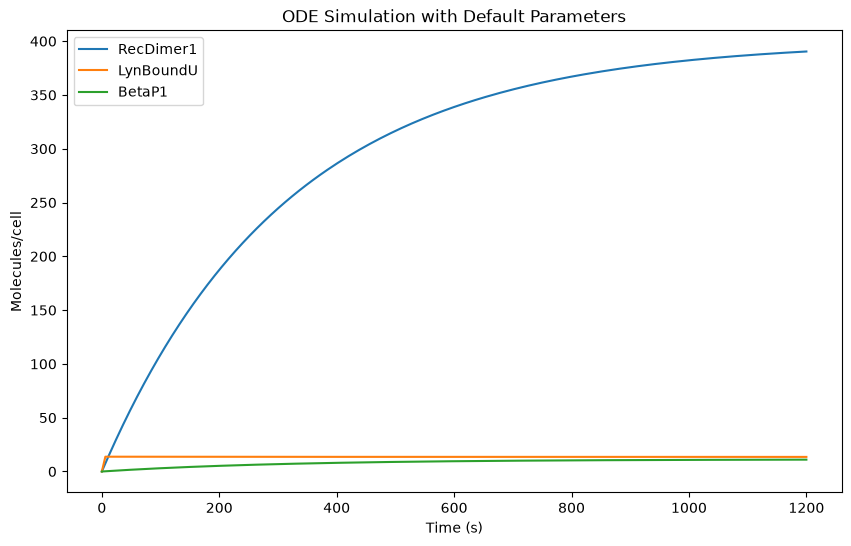

In [3]:
result = simulator.simulate(t_end=1200, n_steps=200)

plt.figure(figsize=(10, 6))
for obs in ["RecDimer1", "LynBoundU", "BetaP1"]:
    plt.plot(result["time"], result[obs], label=obs)
plt.xlabel("Time (s)")
plt.ylabel("Molecules/cell")
plt.title("ODE Simulation with Default Parameters")
plt.legend()
plt.show()

### Local sensitivity analysis

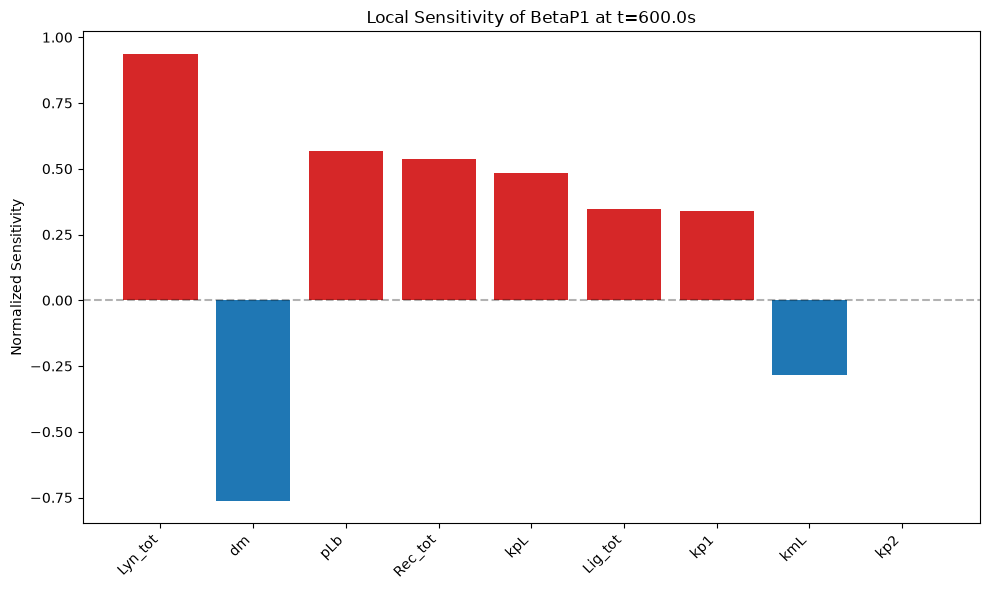

In [4]:
sensitivities = simulator.local_sensitivity_analysis(observable="BetaP1", t_end=600, n_steps=200)

simulator.plot_local_sensitivity(sensitivities=sensitivities, observable="BetaP1", time_index=-1)

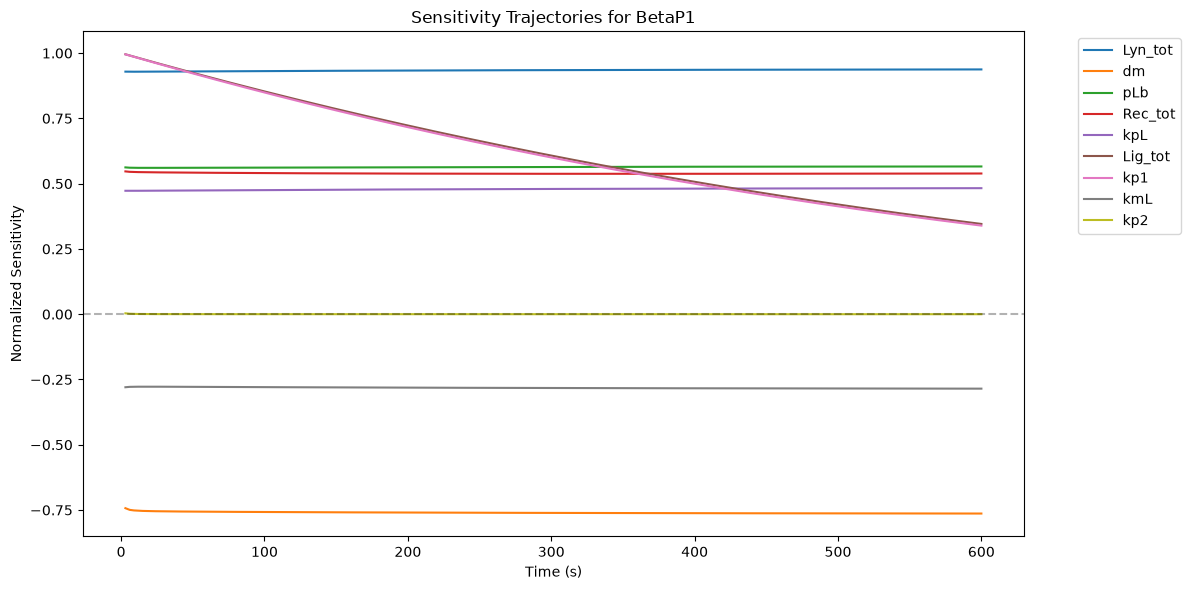

In [5]:
simulator.plot_sensitivity_trajectories(sensitivities=sensitivities, observable="BetaP1", top_n=10)

### Analytic and finite-difference sensitivities

The two methods should agree to several digits. Finite differences need one extra simulation per parameter and their
accuracy depends on the step size; forward sensitivities do not.

In [6]:
fd = simulator.local_sensitivity_analysis(observable="BetaP1", t_end=600, n_steps=200, method="fd")
print(f"{'parameter':10s} {'analytic':>10s} {'finite diff':>12s}")
for p in simulator.parameters:
    print(f"{p:10s} {sensitivities[p][-1]:10.5f} {fd[p][-1]:12.5f}")

parameter    analytic  finite diff
Lig_tot       0.34571      0.34567
Rec_tot       0.53888      0.53888
Lyn_tot       0.93746      0.93748
kp1           0.33934      0.33930
km1          -0.00000      0.00000
kp2           0.00002      0.00006
km2          -0.00000      0.00000
kpL           0.48269      0.48270
kmL          -0.28508     -0.28504
pLb           0.56580      0.56576
dm           -0.76338     -0.76329


### Global sensitivity analysis

In [7]:
coeffs, r2, outputs, log_samples = simulator.global_sensitivity_analysis(
    observable="BetaP1",
    t_end=600,
    n_steps=200,
    n_samples=1000,
    oom_range=2.0,
    seed=42,
)

Sampling 11 parameters using Latin Hypercube
Parameters: ['Lig_tot', 'Rec_tot', 'Lyn_tot', 'kp1', 'km1', 'kp2', 'km2', 'kpL', 'kmL', 'pLb', 'dm']
Generated 1000 samples
Sample quality (discrepancy): 0.0050

Running simulations...



Simulation complete!
  Successful: 1000/1000 (100.0%)
  Failed: 0/1000 (0.0%)

Output range (valid): [2.80e-08, 5.89e+03]

R² score: 0.8027

Global sensitivity coefficients:
  Lig_tot     : +0.5001
  Rec_tot     : +0.6472
  Lyn_tot     : +0.7138
  kp1         : +0.3826
  km1         : +0.0036
  kp2         : +0.0144
  km2         : -0.0282
  kpL         : +0.3501
  kmL         : -0.2220
  pLb         : +0.6280
  dm          : -0.7493


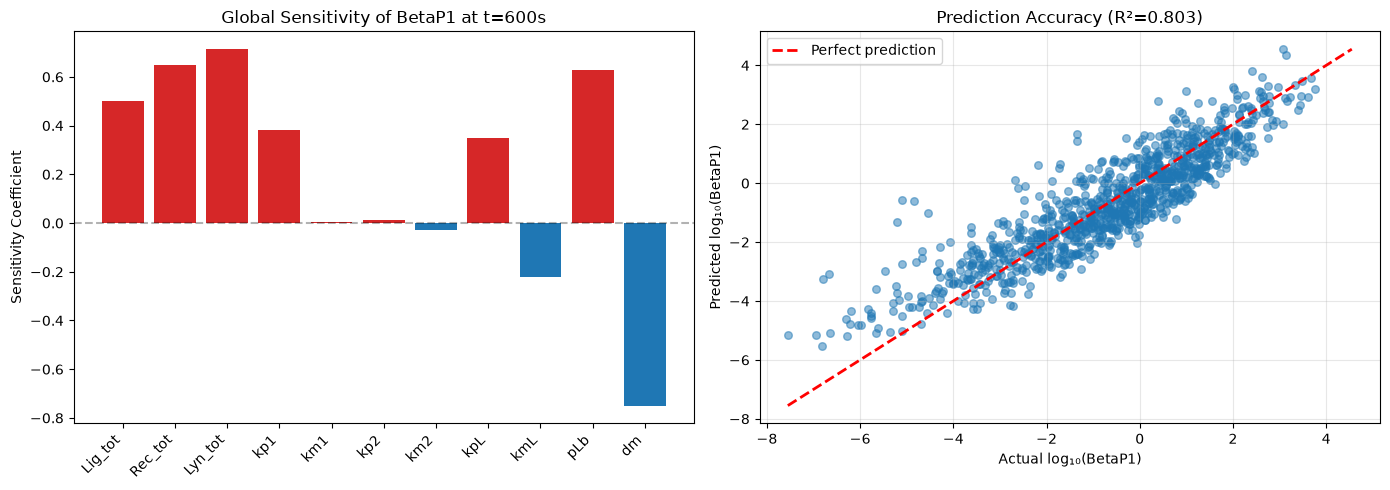

In [8]:
simulator.plot_global_sensitivity(
    sensitivity_coeffs=coeffs,
    r2_score=r2,
    observable="BetaP1",
    outputs=outputs,
    log_samples=log_samples,
    t_end=600,
)

### Several observables at once

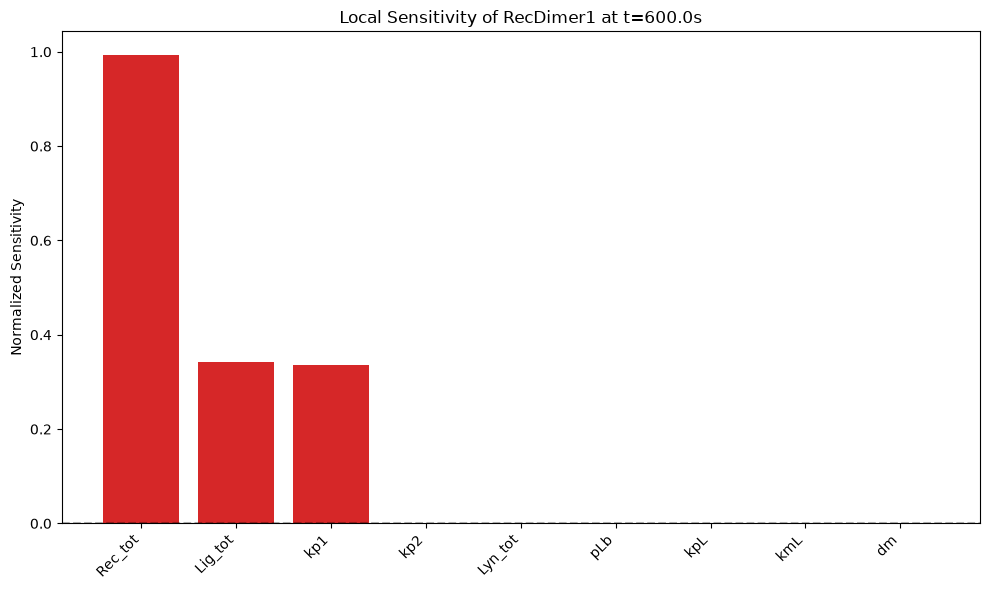

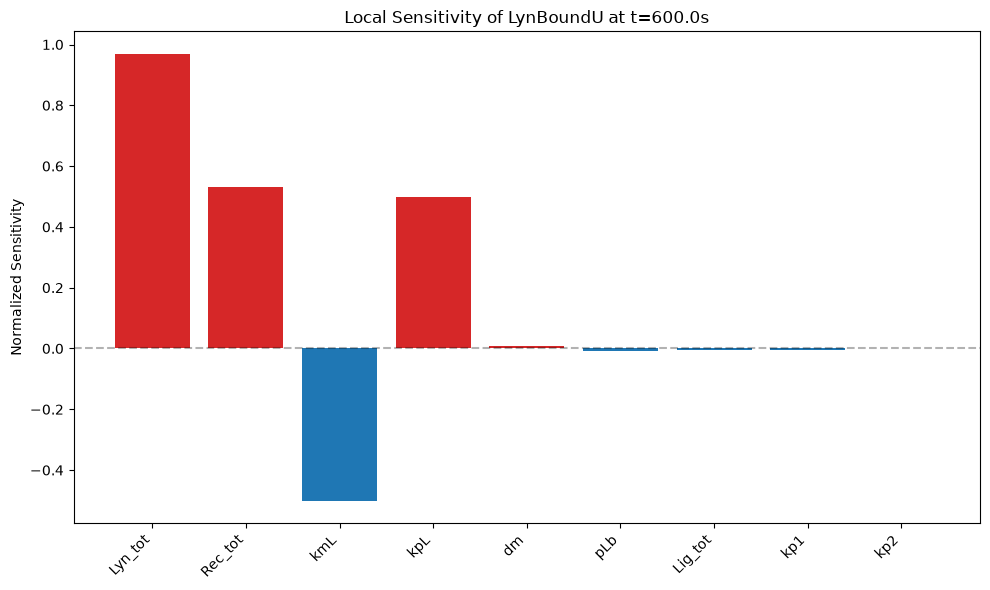

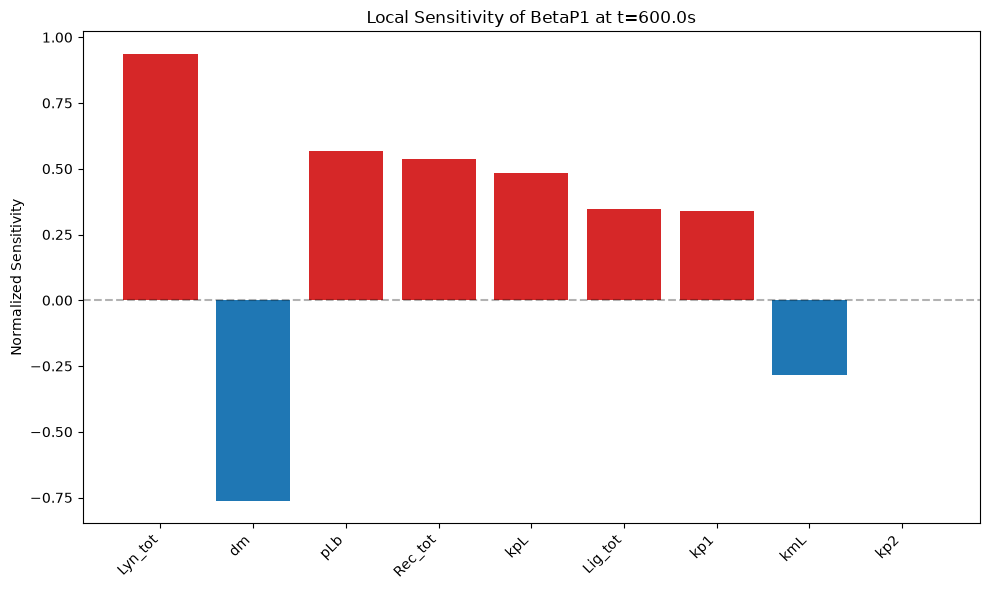

In [9]:
observables_to_analyze = ["RecDimer1", "LynBoundU", "BetaP1"]
sens_all = simulator.local_sensitivity_analysis(observables=observables_to_analyze, t_end=600, n_steps=200)

for obs in observables_to_analyze:
    simulator.plot_local_sensitivity(sensitivities=sens_all, observable=obs, time_index=-1)

### A subset of parameters

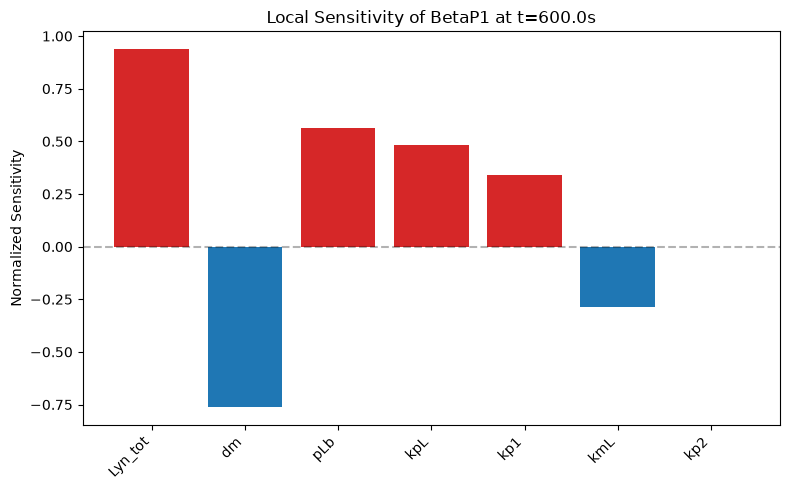

In [10]:
params_of_interest = ["Lyn_tot", "kp1", "kp2", "kpL", "kmL", "pLb", "dm"]

sens_subset = simulator.local_sensitivity_analysis(
    observable="BetaP1", parameters=params_of_interest, t_end=600, n_steps=200
)
simulator.plot_local_sensitivity(sensitivities=sens_subset, observable="BetaP1", time_index=-1, figsize=(8, 5))